This notebook analyses the data previously published by [Thévenot et al. (2015)](https://doi.org/10.1021/acs.jproteome.5b00354) based on the work described in [Mendez et al. (2019)](https://doi.org/10.1007/s11306-019-1612-4).
The data was made "dirty" and then "cleaned" with different imputation strategies.

This notebook was written by Nikolai Egorov

## 1. Import Packages

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV
from sklearn.preprocessing   import StandardScaler
from sklearn.ensemble        import RandomForestClassifier
from sklearn.metrics         import roc_curve, auc as calc_auc
from sklearn.inspection import permutation_importance

print('All packages successfully loaded')

All packages successfully loaded


## 2. Load Data & Peak Sheet

In [32]:
raw_url = 'https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS90.xlsx'

if not os.path.exists('../data/MTBLS90.xlsx'):
    # Download the file
    response = requests.get(raw_url)
    with open('../data/MTBLS90.xlsx', 'wb') as f:
        f.write(response.content)

DataTable = pd.read_excel('../data/MTBLS90.xlsx', sheet_name='Data')
PeakTable = pd.read_excel('../data/MTBLS90.xlsx', sheet_name='Peak')

C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


##  3. Extract X & Y

In [33]:
# Extract PeakList
PeakList = PeakTable['Name']

# Select Subset of Data
DataTable2 = DataTable[(DataTable.Class == 1) | (DataTable.Class == 0)]

Y = DataTable2['Class'].values

# Split Data into Train (2/3) and Test (1/3)
DataTrain, DataTest, YTrain, YTest = train_test_split(DataTable2, Y, test_size=1/3, stratify=Y, random_state=8)

# Extract and Preprocess Train Data
XTrain = DataTrain[PeakList]
XTrainLog = np.log(XTrain)

# Scale data using StandardScaler
scaler = StandardScaler()
XTrainScale = scaler.fit_transform(XTrainLog)

# Extract and Preprocess Test Data
XTest = DataTest[PeakList]
XTestLog = np.log(XTest)

# Scale test data using the same scaler fitted on training data
XTestScale = scaler.transform(XTestLog)

## 4. Hyperparameters Optimisation

AUC → best score: 0.8250, params: {'max_depth': np.int64(7), 'min_samples_leaf': np.float64(0.01)}


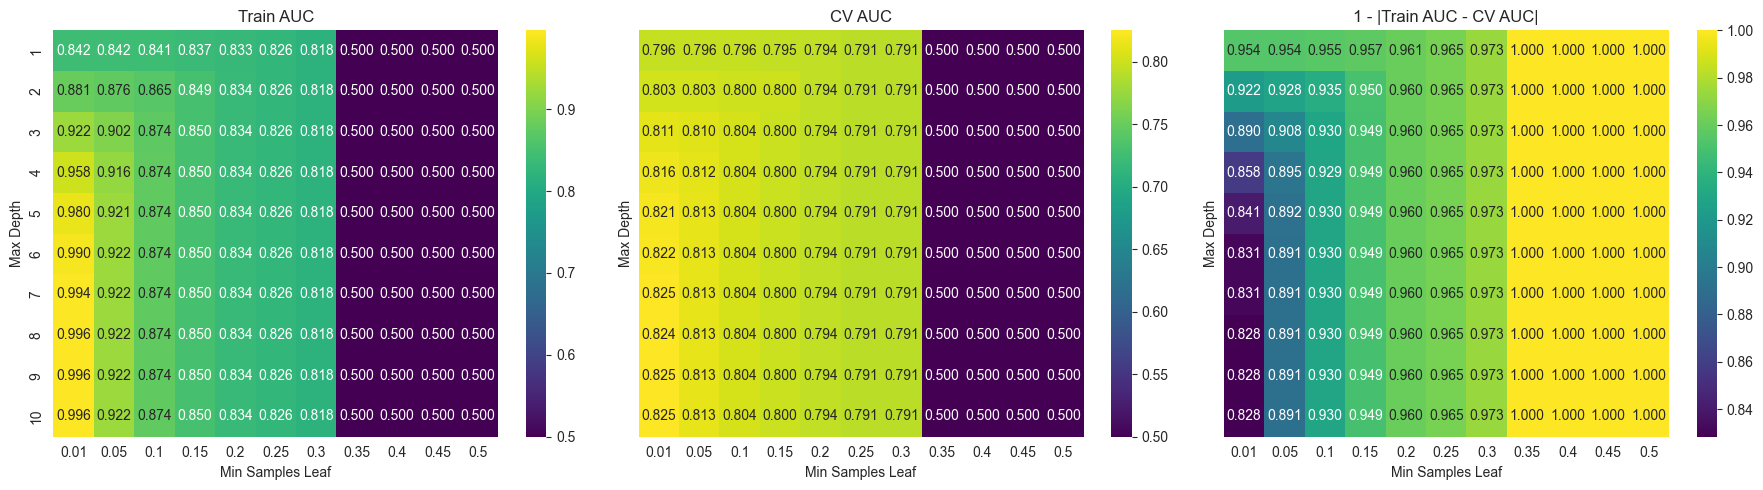

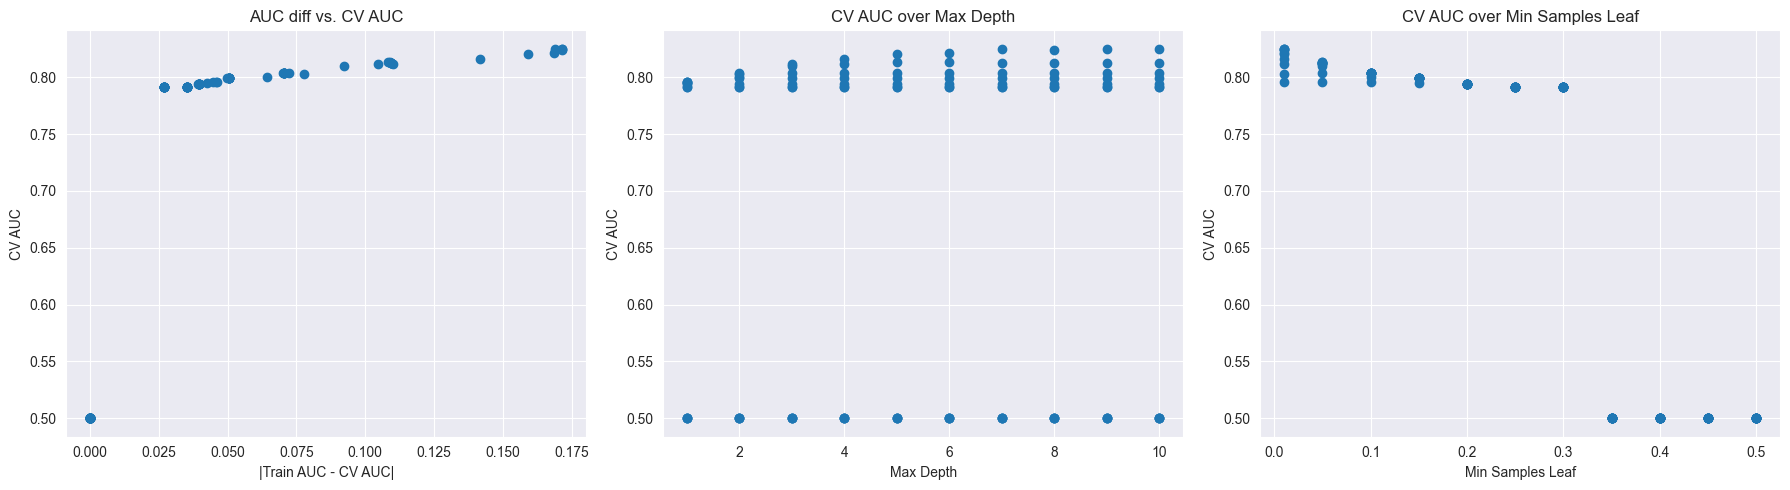

In [34]:
# Model Selection and Evaluation with Random Forest

# 1. Define the parameter grid (similar to the cb package param_dict)
depth = list(range(1,11))
leaf_asfraction = [0.01,0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5]

param_grid = {
    'max_depth'         : depth,
    'min_samples_leaf'  : leaf_asfraction,
    'max_features'      : ['sqrt'],
    'criterion'         : ['gini'],
    'min_samples_split' : [2],
    'max_leaf_nodes'    : [None],
    'n_estimators'      : [100]
}

# 2. Repeated 5-fold CV (10 repeats)
# The original cb.cross_val.KFold(..., folds=5, n_mc=10) helper was doing 10 Monte-Carlo repeats of 5-fold CV, and then averaging the results. In scikit-learn, the most direct analogue is
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=8)

grid = GridSearchCV(
    estimator      = RandomForestClassifier(random_state=8),
    param_grid     = param_grid,
    cv             = cv,
    scoring        = 'roc_auc',
    return_train_score = True,
    n_jobs         = -1
)

grid.fit(XTrainScale, YTrain)

# 3. Extract CV results into a DataFrame
# Get the best model and its hyperparameters
best_rf_model = grid.best_estimator_
best_params = grid.best_params_
results = pd.DataFrame(grid.cv_results_)

# Best params
best_auc_idx = results['mean_test_score'].idxmax()
best_auc_score = results.loc[best_auc_idx, 'mean_test_score']
best_auc_params = {
    'max_depth'        : results.loc[best_auc_idx, 'param_max_depth'],
    'min_samples_leaf' : results.loc[best_auc_idx, 'param_min_samples_leaf']
}

print(f"AUC → best score: {best_auc_score:.4f}, params: {best_auc_params}")

# 4. Build the pivots for AUCfull/AUCcv
pivot_auc_full  = results.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_train_score')
pivot_auc_cv    = results.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score')
pivot_diff_auc  = (pivot_auc_full - pivot_auc_cv).abs()
pivot_inv_auc   = 1 - pivot_diff_auc

def plot_heatmaps():
    """
    Plot heatmaps for the chosen metric:
      - metric='auc': plots AUC full, AUC CV, and 1 - abs(AUC_full - AUC_CV)
      - metric='r2' : plots R^2, Q^2 (test R^2), and 1 - abs(R^2 - Q^2)
    """
    
    full = pivot_auc_full
    cv   = pivot_auc_cv
    inv  = pivot_inv_auc
    titles = ['Train AUC', 'CV AUC', '1 - |Train AUC - CV AUC|']
    matrices = [full, cv, inv]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
    for ax, mat, title in zip(axes, matrices, titles):
        sns.heatmap(mat, ax=ax, annot=True, fmt='.3f', cmap='viridis')
        ax.set_xlabel('Min Samples Leaf')
        ax.set_ylabel('Max Depth')
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_scatter():
    """
    Plot scatter plots for the chosen metric:
      - metric='auc': 1) |Train AUC - CV AUC| vs CV AUC
                      2) CV AUC vs Max Depth
                      3) CV AUC vs Min Samples Leaf
      - metric='r2' :  1) Train R² vs Max Depth
                      2) Train R² vs Min Samples Leaf
                      3) Test R² (Q²) vs Max Depth
                      4) Test R² (Q²) vs Min Samples Leaf
                      5) |Train R² - Q²| vs Q²
    """
    
    diff = pivot_diff_auc.stack()
    cv   = pivot_auc_cv.stack()
    depths = [d for d, l in diff.index]
    leafs  = [l for d, l in diff.index]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(diff, cv)
    axes[0].set_xlabel('|Train AUC - CV AUC|')
    axes[0].set_ylabel('CV AUC')
    axes[0].set_title('AUC diff vs. CV AUC')

    axes[1].scatter(depths, cv)
    axes[1].set_xlabel('Max Depth')
    axes[1].set_ylabel('CV AUC')
    axes[1].set_title('CV AUC over Max Depth')

    axes[2].scatter(leafs, cv)
    axes[2].set_xlabel('Min Samples Leaf')
    axes[2].set_ylabel('CV AUC')
    axes[2].set_title('CV AUC over Min Samples Leaf')

    plt.tight_layout()
    plt.show()

# Example usage:
plot_heatmaps()
plot_scatter()

## 5. Build Model & Evaluate

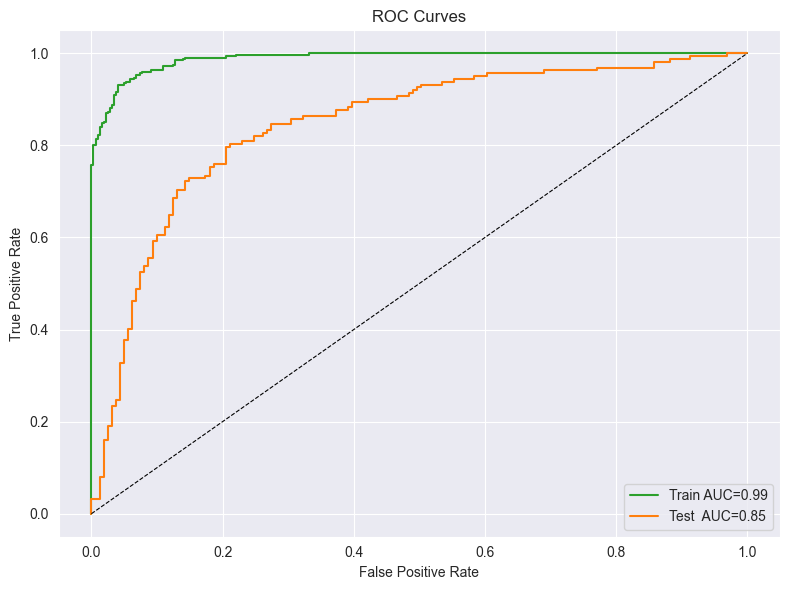

  Set      AUC  Accuracy
Train 0.988924  0.939535
 Test 0.845257  0.777090


In [35]:
# --- 1) FIT FINAL MODEL ----------------------------------------
best_rf_model.fit(XTrainScale, YTrain)

# --- 2) PREDICTIONS & PROBABILITIES ----------------------------
# labels
Y_pred_train = best_rf_model.predict(XTrainScale)
Y_pred_test  = best_rf_model.predict(XTestScale)
# probabilities (positive class)
proba_train  = best_rf_model.predict_proba(XTrainScale)[:, 1]
proba_test   = best_rf_model.predict_proba(XTestScale)[:, 1]

# --- 4) PLOT ROC CURVE --------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# Train ROC
fpr_tr, tpr_tr, _ = roc_curve(YTrain, proba_train)
auc_tr = calc_auc(fpr_tr, tpr_tr)
ax.plot(fpr_tr, tpr_tr, label=f'Train AUC={auc_tr:.2f}', color='C2')

# Test ROC
fpr_te, tpr_te, _ = roc_curve(YTest, proba_test)
auc_te = calc_auc(fpr_te, tpr_te)
ax.plot(fpr_te, tpr_te, label=f'Test  AUC={auc_te:.2f}', color='C1')

# Diagonal
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves')
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# --- 5) STATISTICAL SUMMARIES -----------------------------------

# assemble and print results
# Train accuracy
acc_train = accuracy_score(YTrain, Y_pred_train)

# Test accuracy
acc_test  = accuracy_score(YTest,  Y_pred_test)

summary = pd.DataFrame({
    'Set'          : ['Train', 'Test'],
    'AUC'          : [auc_tr, auc_te],
    'Accuracy' : [acc_train, acc_test]
})

print(summary.to_string(index=False))

## 6. Extract important features

In [36]:
# Build a Name→Label dict
name_to_label = dict(zip(PeakTable['Name'], PeakTable['Label']))

# run on your held-out test set
perm = permutation_importance(
    best_rf_model, 
    XTestScale, 
    YTest, 
    n_repeats=10, 
    random_state=0, 
    n_jobs=-1
)

# sort by mean importance
perm_idx = perm.importances_mean.argsort()[::-1][:3]

print("Top features by permutation importance:")
for i in perm_idx:
    name = PeakList[i]
    label = name_to_label[name]
    mean_imp = perm.importances_mean[i]
    std_imp  = perm.importances_std[i]
    print(f"{label}: {mean_imp:.4f} ± {std_imp:.4f}")

Top features by permutation importance:
Creatine: 0.0105 ± 0.0084
Indolelactic acid: 0.0102 ± 0.0034
Creatinine: 0.0080 ± 0.0052
